# 01 Data Preparation

This section load, clean and filter the JobStreet Malaysia dataset to entry-level roles, run EDA, and build/evaluate the skill dictionary.

Run with **Restart > Run All**. Outputs: `../data/jobs_raw.csv`, `../data/jobs_entry.csv`.

# 1. Setup

In [1]:
import sys, re
from pathlib import Path
from collections import Counter

import pandas as pd
from rapidfuzz import fuzz
import matplotlib.pyplot as plt
import spacy

sys.path.append("..")   # so modules/ is importable from notebooks/
pd.set_option("display.max_colwidth", 120)

# 2. Load data

In [2]:
RAW = Path("../data/jobs_raw.csv")

if RAW.exists():
    df = pd.read_csv(RAW)
else:
    from datasets import load_dataset
    df = load_dataset("azrai99/job-dataset")["train"].to_pandas()
    RAW.parent.mkdir(exist_ok=True)
    df.to_csv(RAW, index=False)

print(df.shape)
print(df.columns.tolist())
df.head()

(59306, 11)
['job_id', 'job_title', 'company', 'descriptions', 'location', 'category', 'subcategory', 'role', 'type', 'salary', 'listingDate']


,job_id,job_title,company,descriptions,location,category,subcategory,role,type,salary,listingDate
0,74630583,Procurement Executive (Contract),Coca-Cola Bottlers (Malaysia) Sdn Bhd,"Position Purpose\nManage aspects of procurement including supplier management, contract management, and vendor perfo...",Negeri Sembilan,"Manufacturing, Transport & Logistics","Purchasing, Procurement & Inventory",procurement-executive,Contract/Temp,NaN,2024-03-21T05:58:35Z
1,74660602,Account Executive/ Assistant,Acoustic & Lighting System Sdn Bhd,We are looking for a Account Executive/ Assistant to join our team.\nWhat you will get when you join us:\nFair work ...,Petaling,Accounting,Bookkeeping & Small Practice Accounting,executive-assistant,Full time,"RM 2,800 – RM 3,200 per month",2024-03-22T06:52:57Z
2,74655679,"Data Analyst - Asset Management, SPX Express",Shopee Mobile Malaysia Sdn Bhd,Performs detailed data analysis on existing spendings / consumptions of SPX and identifies cost saving areas.\nPlan ...,Klang District,"Manufacturing, Transport & Logistics",Analysis & Reporting,asset-management-analyst,Full time,NaN,2024-03-22T04:22:43Z
3,74657624,Service Engineer,Sun Medical Systems Sdn Bhd,"You are important for troubleshooting, installation, maintenance and service repair needs on designated equipment.\n...",Petaling,Engineering,Electrical/Electronic Engineering,services-engineer,Full time,"RM 3,000 – RM 3,500 per month",2024-03-22T05:32:09Z
4,74679363,Purchasing Executive,Magnet Security & Automation Sdn. Bhd.,"MAG is a trailblazer in the industry, boasting an extensive track record of over four decades, rich in technical exp...",Hulu Langat,"Manufacturing, Transport & Logistics","Purchasing, Procurement & Inventory",purchasing-executive,Full time,"RM 2,800 – RM 3,500 per month",2024-03-23T03:56:39Z


# 3. Inspect

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 59306 entries, 0 to 59305
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   job_id        59306 non-null  int64
 1   job_title     59306 non-null  str  
 2   company       59306 non-null  str  
 3   descriptions  59306 non-null  str  
 4   location      59306 non-null  str  
 5   category      59306 non-null  str  
 6   subcategory   59306 non-null  str  
 7   role          57370 non-null  str  
 8   type          59306 non-null  str  
 9   salary        26641 non-null  str  
 10  listingDate   59306 non-null  str  
dtypes: int64(1), str(10)
memory usage: 121.4 MB


In [4]:
print("Missing values:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
job_id              0
job_title           0
company             0
descriptions        0
location            0
category            0
subcategory         0
role             1936
type                0
salary          32665
listingDate         0
dtype: int64

Duplicate rows: 0


In [5]:
df.sample(3, random_state=1).T

,11516,209,1609
job_id,74019850,74598206,74610214
job_title,Office Admin Assistant,Junior Chemical Process (Beneficiation Direction),General Clerk & Site Supervisor
company,SIN-KUNG LOGISTICS BERHAD,Esteel Enterprise Sabah Sdn Bhd,Cyco Fire Tech Sdn Bhd
descriptions,"Job Description:\nAs an Office Admin Assistant, you will be responsible for providing administrative support to ensu...",Responsibilities:\n• Production Process Design: Assist in designing and optimizing mining processing production proc...,"Assist on procurement and documentation.\nIssuing and record Confirmation Order, Delivery Order and Invoices Purchas..."
location,Shah Alam/Subang,Sipitang District,Kajang/Bangi/Serdang
category,Administration & Office Support,Engineering,Administration & Office Support
subcategory,Administrative Assistants,Chemical Engineering,Administrative Assistants
role,office-administrator,NaN,site-supervisor
type,Full time,Full time,Full time
salary,NaN,"RM 2,500 – RM 3,500 per month","RM 1,800 – RM 2,500 per month"


# 4. Clean

In [ ]:
n0 = len(df)
df = df.drop_duplicates(subset=["job_title", "company", "descriptions"])
n1 = len(df)
df = df[df["descriptions"].str.strip().str.len() > 100]
n2 = len(df)
print(f"raw: {n0} | after de-duplication: {n1} | after removing short/empty descriptions: {n2}")

df["listingDate"] = pd.to_datetime(df["listingDate"])


def _clean_display_text(text):
    """Light cleanup for display only -- keeps line breaks, unlike the heavy whitespace
    collapse below (that one feeds the embeddings and must not change, so notebook 02's
    texts hash stays valid and nothing needs re-encoding).
    """
    lines = [line.rstrip() for line in text.split("\n")]
    text = "\n".join(lines)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()


df["description_display"] = df["descriptions"].apply(_clean_display_text)
df["descriptions"] = df["descriptions"].str.replace(r"\s+", " ", regex=True).str.strip()

Exact duplicates (`drop_duplicates` above) only catch postings that are byte-identical. Recruiters
commonly repost the same vacancy with a trivial edit (a reworded header line, a fixed typo), which
survives that check. The cell below catches these: postings with the same `job_title`, `company`
**and `location`** (location is part of the key so that the same ad posted for several branches --
a real, distinct opening per branch -- is not wrongly treated as a duplicate) whose descriptions are
at least 90% similar (`rapidfuzz.fuzz.ratio`) are treated as the same posting, and only the earliest
by `listingDate` is kept.

In [7]:
n2 = len(df)
near_dup_idx = set()
for _, g in df.groupby(["job_title", "company", "location"]):
    if len(g) < 2:
        continue
    g = g.sort_values("listingDate")
    descs = g["descriptions"].tolist()
    idxs = g.index.tolist()
    kept = [0]
    for i in range(1, len(descs)):
        if any(fuzz.ratio(descs[i], descs[k]) >= 90 for k in kept):
            near_dup_idx.add(idxs[i])
        else:
            kept.append(i)
df = df.drop(index=near_dup_idx)
n3 = len(df)
print(f"after removing near-duplicate postings (same title+company+location, >=90% similar): {n3} (-{n2 - n3})")

after removing near-duplicate postings (same title+company+location, >=90% similar): 54922 (-863)


# 5. Entry-level filter

## 5.1 Required years of experience
The regex needed iterative refinement. Two false-positive sources were found and removed:
- **Age requirements** ("at least 18 years old") were read as 18 years of experience.
- **Company history** ("18 years of experience in facilities management") was read as a candidate requirement.

Final rule: strip age phrases first, then require "experience" shortly after the number of years.

In [8]:
def min_years(text):
    text = text.lower()

    # strip age-related phrases first
    text = re.sub(r"\d+\s*years?\s*(old|of age|and above|& above)", "", text)
    text = re.sub(r"(age|aged)\s*:?\s*\d+", "", text)

    # years followed by "experience" (a few words allowed in between)
    m = re.findall(r"(\d+)\s*(?:\+|-\s*\d+)?\s*(?:years?|yrs?)[^.]{0,25}?experience", text)
    nums = [int(x) for x in m if int(x) < 20]
    return min(nums) if nums else None


# regression tests for the bugs above
age_cases = [
    "Job Requirements Min. 18 years and above; Good communication skills",
    "Must be at least 18 years old. Fresh graduates are encouraged to apply.",
    "Greets customers... High school diploma or equivalent At least 18 years old",
    "At least 18 years old and above 4) Dedicated and pleasant personality",
]
exp_cases = [
    "At least 5 years of working experience preferably in managing F&B outlets",
    "Minimum 5 years' experience on construction projects",
    "5 years\u2019 experience in technical selling in Azure and M365 solutions",
]
assert all(min_years(s) is None for s in age_cases)
assert all(min_years(s) == 5 for s in exp_cases)

df["min_years"] = df["descriptions"].apply(min_years)
df["min_years"].value_counts(dropna=False).sort_index()

min_years
0.0       113
1.0      5579
2.0      6972
3.0      5885
4.0      1043
5.0      4443
6.0       399
7.0       402
8.0       657
9.0        19
10.0      772
11.0        3
12.0       83
13.0        5
14.0        3
15.0      165
16.0        6
17.0        1
18.0        6
NaN     28366
Name: count, dtype: int64

## 5.2 Title and keyyword rules
`assistant` and `associate` are excluded from the entry pattern (they also appear in senior titles such as *Assistant Manager*). `specialist` is excluded from the senior pattern because it is a mixed role name in Malaysian postings.

In [9]:
title = df["job_title"].fillna("").astype("string").str.lower()
description = df["descriptions"].fillna("").astype("string").str.lower()

senior_pattern = (
    r"\b(?:senior|sr\.?|lead|principal|manager|director|head|chief|"
    r"supervisor|vice president|vp|consultant|architect)\b"
)
entry_pattern = (
    r"\b(?:fresh graduate(?:s)?|entry[- ]level|no experience|"
    r"without experience|junior|trainee|intern|graduate program)\b"
)

df["is_senior_title"] = title.str.contains(senior_pattern, regex=True, na=False)
df["entry_signal"] = (
    title.str.contains(entry_pattern, regex=True, na=False)
    | description.str.contains(entry_pattern, regex=True, na=False)
)

## 5.3 Apply the filter
Entry-level = not a senior title AND (stated experience <= 1 year, OR no stated experience but an entry-level signal).

In [10]:
entry_df = df[
    ~df["is_senior_title"]
    & (
        (df["min_years"] <= 1)
        | (df["min_years"].isna() & df["entry_signal"])
    )
].copy()

print(len(entry_df), "of", len(df), f"({len(entry_df)/len(df)*100:.1f}%)")
entry_df["category"].value_counts().head(10)

10956 of 54922 (19.9%)


category
Accounting                                1908
Administration & Office Support           1724
Information & Communication Technology    1248
Engineering                               1202
Sales                                      885
Manufacturing, Transport & Logistics       701
Human Resources & Recruitment              560
Marketing & Communications                 535
Call Centre & Customer Service             399
Banking & Financial Services               376
Name: count, dtype: int64

## 5.4 Validation by manual inspection

In [11]:
#included rows (should all look entry-level)
entry_df.sample(15, random_state=1)[["job_title", "min_years", "entry_signal"]]

,job_title,min_years,entry_signal
13215,Sales Admin Support,NaN,True
2919,Personal Banker ( April 2024 Intake I Nationwide I Fresh Grad) - P14,NaN,True
53548,"Assistant, Sales and Marketing Administration Support (FMCG)",1.0,True
53078,Customer Relation Admin Coordinator,1.0,True
45622,Marketing Executive ( Fresh Graduate),NaN,True
42390,Sales Associate - TRX,1.0,False
18898,"Intern, Life Branch Operation – Customer Service Division",NaN,True
45727,Software Developer (.NET C#),1.0,False
35435,Finance Intern,NaN,True
24108,Foreman/ Mechanic,1.0,True


In [12]:
# excluded senior titles (should all look senior)
df[df["is_senior_title"]][["job_title"]].sample(10, random_state=1)

,job_title
44001,Senior Accounting Associate - Accounting Services
5232,Senior Structure Engineer
6774,Senior Software Engineer
34112,Finance Manager
24989,Senior Structural Engineer
7452,HR & Operations Manager
35650,Manager - Credit Admin - Johor Bahru
2448,Senior Product Specialist (Life Sciences)
2682,Tech Sales Consultant – Digital Security Solution
19157,STEP Developer Senior Engineer


In [13]:
entry_df.to_csv("../data/jobs_entry.csv", index=False)

# 6. Exploratonary data analysis

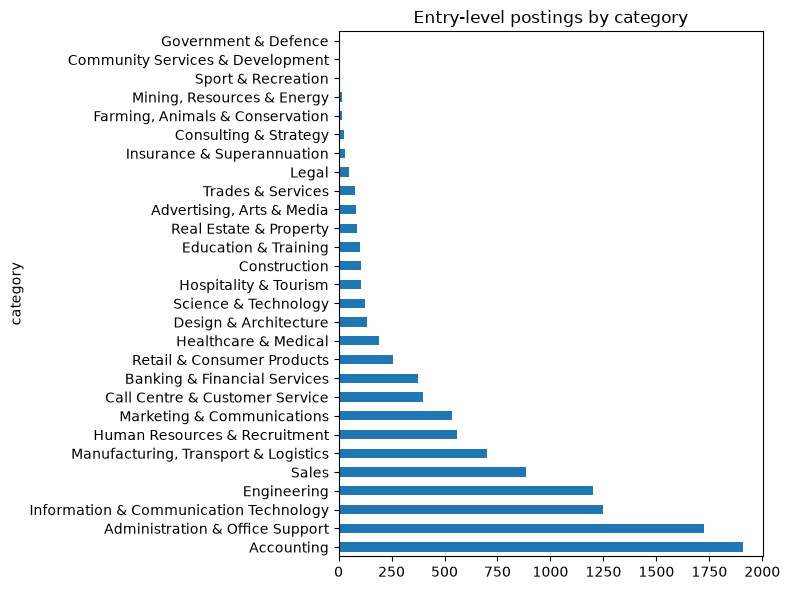

In [14]:
entry_df["category"].value_counts().plot(kind="barh", figsize=(8, 6), title="Entry-level postings by category")
plt.tight_layout()
plt.show()

Accounting, Administration, ICT and Engineering dominate. Several categories (e.g. Government & Defence, Community Services) have almost no entry-level postings.

In [15]:
entry_df["location"].value_counts().head(15)

location
Kuala Lumpur                2351
Petaling                    2023
Johor Bahru District         871
Selangor                     574
Shah Alam/Subang             499
Penang Island                353
Seberang Perai               325
Penang                       314
Kuala Lumpur City Centre     296
Klang District               256
Hulu Langat                  216
Kajang/Bangi/Serdang         194
Johor                        153
Kuching Division             128
Kinta District               124
Name: count, dtype: int64

Postings are concentrated in the Klang Valley (Kuala Lumpur, Petaling, Selangor) and Johor Bahru. East Malaysia is thinly represented. This is a limitation of the platform's coverage.

In [16]:
entry_df["descriptions"].str.len().describe()

count    10956.000000
mean      1646.594651
std        956.371919
min        102.000000
25%       1005.750000
50%       1438.000000
75%       2046.000000
max      12332.000000
Name: descriptions, dtype: float64

Mean about 1,650 characters, median about 1,440, max over 12,000. Longer descriptions will be truncated by the SBERT model, so the embedding strategy must be decided explicitly (full text vs. requirements section only).

In [17]:
entry_df["type"].value_counts()

type
Full time          9678
Contract/Temp      1048
Casual/Vacation     140
Part time            90
Name: count, dtype: int64

In [18]:
entry_df["subcategory"].value_counts().head(15)

subcategory
Administrative Assistants                  1248
Bookkeeping & Small Practice Accounting     948
Electrical/Electronic Engineering           384
Consulting & Generalist HR                  349
Account & Relationship Management           332
Purchasing, Procurement & Inventory         297
Developers/Programmers                      283
Financial Accounting & Reporting            268
Sales Representatives/Consultants           259
Marketing Communications                    252
Help Desk & IT Support                      251
Customer Service - Call Centre              249
Other                                       236
Mechanical Engineering                      223
Audit - External                            174
Name: count, dtype: int64

# 7. Skill dictionary construction
Corpus-driven: candidate terms are mined from the full entry-level dataset, then reviewed manually (keep / merge into a canonical term / drop). The reviewed result is stored in `modules/skill_dictionary.py`.

## 7.1 Candidate mining: context patterns

In [19]:
context_pattern = re.compile(
    r"(?:experience (?:with|in)|proficient in|knowledge of|familiar(?:ity)? with|skilled in)\s+([a-zA-Z0-9\+\#\.\s]{2,40}?)(?:[.,;\n]|and\b)",
    re.IGNORECASE,
)

candidate_counter = Counter()
for desc in entry_df["descriptions"]:
    for m in context_pattern.findall(desc.lower()):
        term = m.strip()
        if 2 <= len(term) <= 40:
            candidate_counter[term] += 1

print(len(candidate_counter), "distinct candidate terms")
candidate_counter.most_common(400)

3558 distinct candidate terms


[('microsoft office', 165),
 ('related field', 132),
 ('english', 118),
 ('the related field', 118),
 ('ms office', 82),
 ('sales', 78),
 ('accounting', 57),
 ('logistics', 51),
 ('microsoft excel', 49),
 ('written', 45),
 ('both written', 40),
 ('microsoft word', 39),
 ('microsoft office applications', 36),
 ('customer service', 29),
 ('mandarin', 27),
 ('a similar role', 27),
 ('accounting software', 23),
 ('digital marketing', 22),
 ('the related field is required', 21),
 ('accounting principles', 21),
 ('ms excel', 19),
 ('autocad', 19),
 ('excel', 19),
 ('spoken', 18),
 ('social media platforms', 18),
 ('finance', 17),
 ('microsoft office suite', 16),
 ('sql', 16),
 ('ms office applications', 16),
 ('audit', 14),
 ('a logistics services company', 14),
 ('ms word', 13),
 ('project management', 13),
 ('a related field', 13),
 ('similar capacity', 13),
 ('purchasing', 13),
 ('relevant field', 13),
 ('marketing', 13),
 ('a similar position', 12),
 ('accounting standards', 12),
 ('rela

## 7.2 Manual review
Candidates were reviewed by hand: real skills kept, spelling variants merged into one canonical term (e.g. *ms office* -> *microsoft office*), and sentence fragments dropped (e.g. *the related field*, *a similar role*). Language skills (English, Mandarin, Bahasa Malaysia, ...) are kept in a separate list.

# 8. Dictionary coverage evaluation and targeted expansion
Evaluation and expansion are iterated: coverage is measured, weak categories are mined for new terms, the terms are reviewed manually and added to `modules/skill_dictionary.py`, then coverage is measured again.

## 8.1 Overall coverage

In [20]:
import importlib
import modules.skill_dictionary as sd
importlib.reload(sd)   # pick up edits to skill_dictionary.py without restarting the kernel
from modules.skill_dictionary import (
    SKILLS, ALIASES, LANGUAGES, LANGUAGE_ALIASES, build_matcher, extract_terms
)

nlp = spacy.load("en_core_web_sm")
skill_matcher = build_matcher(nlp, SKILLS, ALIASES)
lang_matcher = build_matcher(nlp, LANGUAGES, LANGUAGE_ALIASES)

entry_df["skills"] = entry_df["descriptions"].apply(lambda t: extract_terms(t, nlp, skill_matcher))
entry_df["languages"] = entry_df["descriptions"].apply(lambda t: extract_terms(t, nlp, lang_matcher))
entry_df["n_skills"] = entry_df["skills"].apply(len)

zero = (entry_df["n_skills"] == 0).sum()
print(f"Dictionary size: {len(SKILLS)} skills, {len(ALIASES)} aliases, {len(LANGUAGES)} languages")
print(f"{zero} of {len(entry_df)} postings with zero skills matched ({zero/len(entry_df)*100:.1f}%)")
entry_df["n_skills"].describe()

Dictionary size: 131 skills, 63 aliases, 5 languages
738 of 10956 postings with zero skills matched (6.7%)


count    10956.000000
mean         3.718145
std          2.408179
min          0.000000
25%          2.000000
50%          3.000000
75%          5.000000
max         21.000000
Name: n_skills, dtype: float64

## 8.2 Coverage by category
Zero-match rate shows where the dictionary finds nothing; mean skills per posting shows how deep the coverage is.

In [21]:
coverage = pd.DataFrame({
    "n": entry_df["category"].value_counts(),
    "zero_pct": entry_df.groupby("category")["n_skills"].apply(lambda s: (s == 0).mean() * 100),
    "mean_skills": entry_df.groupby("category")["n_skills"].mean(),
}).round(1).sort_values("zero_pct", ascending=False)
coverage

,n,zero_pct,mean_skills
category,,,
Sport & Recreation,8,50.0,0.6
"Farming, Animals & Conservation",17,35.3,1.6
Hospitality & Tourism,107,24.3,1.6
Trades & Services,79,24.1,1.8
Legal,48,18.8,2.2
Healthcare & Medical,189,17.5,2.3
Engineering,1202,17.4,2.3
Education & Training,99,17.2,2.4
Community Services & Development,6,16.7,2.5


## 8.3 Weak categories
Rule: at least 20% of postings with zero matches **and** at least 40 postings. Smaller categories are too small to mine reliably and are reported as a limitation instead.

In [22]:
weak_categories = coverage[(coverage["zero_pct"] >= 20) & (coverage["n"] >= 40)].index.tolist()
print(weak_categories)
coverage.loc[weak_categories]

['Hospitality & Tourism', 'Trades & Services']


,n,zero_pct,mean_skills
category,,,
Hospitality & Tourism,107,24.3,1.6
Trades & Services,79,24.1,1.8


## 8.4 Targeted mining in weak categories
Noun phrases are ranked by how much more often they occur in the weak categories than elsewhere. To filter out one employer's repeated postings, a phrase must be used by at least 3 different companies. Terms already in the dictionary are hidden.

Note: Output shown is from round 3. The final review of this list produced the round 4 additions. Mining was stopped after this round because the candidate list contained almost no new skills (2 skills and 4 aliases out of 66 candidates) and the overall zero-match rate had stopped changing by more than about 1 point.

In [23]:
nlp_fast = spacy.load("en_core_web_sm", disable=["ner", "lemmatizer"])
strip_det = re.compile(r"^(the|a|an|our|your|their|this|that|any)\s+")

def mine_phrases(frame):
    """Return phrase -> posting count, and phrase -> set of companies using it."""
    counts, companies = Counter(), {}
    docs = nlp_fast.pipe(frame["descriptions"].str.lower(), batch_size=100)
    for company, doc in zip(frame["company"], docs):
        for ch in doc.noun_chunks:
            t = strip_det.sub("", ch.text.strip())
            if 2 <= len(t.split()) <= 4 and len(t) <= 40:
                counts[t] += 1
                companies.setdefault(t, set()).add(company)
    return counts, companies

weak_mask = entry_df["category"].isin(weak_categories)
weak_df, rest_df = entry_df[weak_mask], entry_df[~weak_mask]
print(len(weak_df), "weak-category postings |", len(rest_df), "others")

weak_c, weak_comp = mine_phrases(weak_df)
rest_c, _ = mine_phrases(rest_df)

MIN_POSTINGS, MIN_COMPANIES = 5, 3
known = set(SKILLS) | set(ALIASES)

rows = []
for phrase, n in weak_c.items():
    if n < MIN_POSTINGS or len(weak_comp[phrase]) < MIN_COMPANIES or phrase in known:
        continue
    expected = rest_c.get(phrase, 0) / len(rest_df) * len(weak_df)   # expected count if no category effect
    rows.append((phrase, n, len(weak_comp[phrase]), round(n / (expected + 1), 2)))

candidates = pd.DataFrame(rows, columns=["phrase", "postings", "companies", "score"]).sort_values("score", ascending=False)
candidates.head(80)

186 weak-category postings | 10770 others


,phrase,postings,companies,score
52,senior chefs,10,3,10.00
43,special requests,9,6,8.70
37,f&b industry,10,5,7.73
41,all guests,9,4,7.25
34,health and safety standards,7,3,6.77
30,customer concerns,9,3,6.69
38,work environment,9,4,6.69
17,service advisor,6,3,5.70
51,high school diploma,10,3,5.68
29,all times,27,15,5.13


In [24]:
pd.set_option("display.max_rows", None)
candidates

,phrase,postings,companies,score
52,senior chefs,10,3,10.00
43,special requests,9,6,8.70
37,f&b industry,10,5,7.73
41,all guests,9,4,7.25
34,health and safety standards,7,3,6.77
30,customer concerns,9,3,6.69
38,work environment,9,4,6.69
17,service advisor,6,3,5.70
51,high school diploma,10,3,5.68
29,all times,27,15,5.13


## 8.5 Iteration log


| Round | Change to dictionary | Data | Zero-match rate |
|---|---|---|---|
| 1 | Seed list + first review (about 100 terms) | 400 per category sample (5,424 postings) | 13.0% |
| 2 | Full-dataset review + aliases, `modules/skill_dictionary.py` | Full entry-level set (11,206) | 6.4% |
| 3 | Weak-category additions (education, construction, healthcare, F&B) | Full entry-level set (11,206) | 5.3% |
| 4 | Final weak-category review: 2 skills and 4 aliases added (137 skills, 64 aliases) | Full entry-level set (11,206) | 4.8% |
| 5 | Precision cleanup: removed ambiguous aliases (network) and industry terms (logistics, retail, manufacturing, insurance, healthcare, electrical); chinese merged into mandarin; near-duplicate postings removed (131 skills, 63 aliases) | Full entry-level set, post near-dup removal (10,956) | 6.7% |